In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 04 · Forecast counterfactual: what would 2025 have looked like?

A second, independent way to ask the question. Instead of comparing the
CBD with other neighbourhoods, forecast the CBD's own daily trips from its
pre-toll history (July 2022-December 2024) and compare the forecast with
what happened. The same is done for the rest of Manhattan, so the two
forecast errors can be compared.

The forecast has to be good enough for this to mean anything, so the
models are first tested on backtests that pretend the toll started on
1 October 2023, 1 January, 1 April or 1 July 2024 (each with at least 15
months of training data, so yearly seasonality can be learned). Nothing
happened on those dates, which makes the backtest error both the accuracy
check and the noise band.

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from congestion.forecast import MODELS, POLICY_START, backtest, fit_predict, score, weekly_interval
from congestion.panel import daily_series, load_weather, load_zone_day
from congestion.plots import COLORS, mark_policy, save, style, write_metrics

style()
series = daily_series(load_zone_day())
weather = load_weather()
END = series["date"].max()
print("Daily series", series["date"].min().date(), "to", END.date())
series.tail(3)

Daily series 2022-01-01 to 2026-08-31


,date,cbd,manhattan,outer
1701,2026-08-29,247991,62243,456850
1702,2026-08-30,210929,56922,399313
1703,2026-08-31,169757,56549,345367


## 1. Backtests (no toll in the test period)

* **Seasonal naive:** same weekday 52 weeks earlier.
* **Regression:** linear trend, day of week, yearly seasonality (Fourier
  terms), holidays, and Central Park rain, snow and temperature.
* **Boosted:** the regression plus gradient boosting on what it misses.

Scores: mean absolute percentage error on days and on weeks, and the
"placebo effect", the average gap between actual and forecast over the
test period. A model that is fit for purpose shows a placebo effect near 0.

In [3]:
bts = {col: backtest(series, col, weather) for col in ["cbd", "manhattan"]}
scores = pd.concat([score(b).assign(series=col) for col, b in bts.items()])
scores = scores[["series", "model", "origin", "daily_mape", "weekly_mape", "placebo_effect", "mape_vs_naive"]]
scores.style.format({"daily_mape": "{:.1%}", "weekly_mape": "{:.1%}", "placebo_effect": "{:+.1%}",
                     "mape_vs_naive": "{:.2f}"})

,series,model,origin,daily_mape,weekly_mape,placebo_effect,mape_vs_naive
0,cbd,boosted,2023-09-30,5.4%,3.2%,-1.0%,0.93
1,cbd,boosted,2023-12-31,6.2%,4.0%,-1.3%,0.83
2,cbd,boosted,2024-03-31,6.2%,4.1%,-0.4%,0.75
3,cbd,boosted,2024-06-30,7.1%,4.9%,-1.4%,0.74
4,cbd,regression,2023-09-30,7.6%,5.4%,-1.0%,1.31
5,cbd,regression,2023-12-31,7.3%,5.4%,-1.4%,0.98
6,cbd,regression,2024-03-31,7.9%,6.4%,-0.1%,0.95
7,cbd,regression,2024-06-30,9.0%,7.4%,-1.3%,0.94
8,cbd,seasonal_naive,2023-09-30,5.8%,3.5%,-0.0%,1.00
9,cbd,seasonal_naive,2023-12-31,7.4%,5.1%,+0.0%,1.00


In [4]:
avg = scores.groupby(["series", "model"])[["weekly_mape", "placebo_effect"]].agg(
    weekly_mape=("weekly_mape", "mean"), placebo_abs=("placebo_effect", lambda x: np.abs(x).mean()))
best = avg.loc["cbd"]["weekly_mape"].idxmin()
print("Chosen model (lowest average weekly error on the CBD backtests):", best)
avg.style.format("{:.1%}")

Chosen model (lowest average weekly error on the CBD backtests): boosted


## 2. The counterfactual

Train on July 2022-December 2024, forecast every day from 5 January 2025
to the end of the data, and compare week by week. The shaded bands are
80% and 95% intervals taken from the backtest errors.

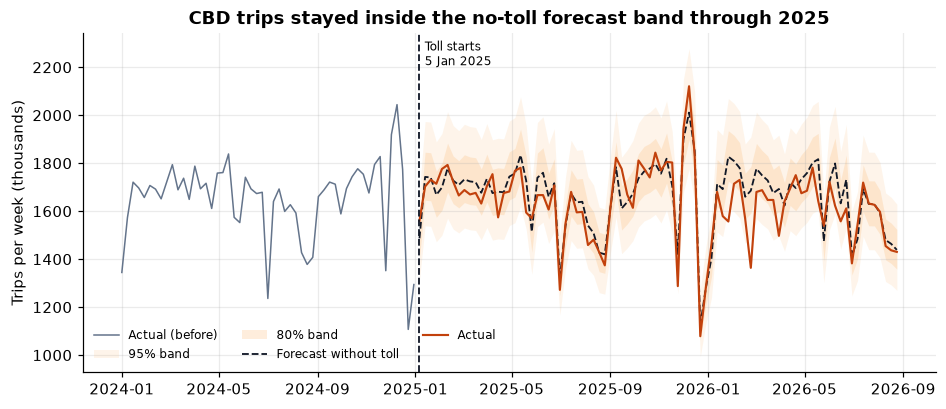

Weekly CBD trips outside the 95% band: 2%


In [5]:
post = series.loc[series["date"] >= POLICY_START, "date"]
res = {}
for col in ["cbd", "manhattan"]:
    pred = {m: fit_predict(series, col, pd.Timestamp("2024-12-31"), post, m, weather) for m in MODELS}
    df = series.loc[post.index, ["date", col]].rename(columns={col: "actual"}).copy()
    for m in MODELS:
        df[m] = np.expm1(pred[m])
    res[col] = df

band = weekly_interval(bts["cbd"], best)
cbd = res["cbd"].copy()
cbd["week"] = cbd["date"] - pd.to_timedelta(cbd["date"].dt.day_of_week, unit="D")
wk = cbd.groupby("week")[["actual", best]].sum()
wk = wk[cbd.groupby("week").size() == 7]           # full weeks only
hist = series.assign(week=series["date"] - pd.to_timedelta(series["date"].dt.day_of_week, unit="D"))
hist_wk = hist.groupby("week")["cbd"].sum()
hist_wk = hist_wk[(hist_wk.index >= "2024-01-01") & (hist_wk.index < POLICY_START)
                  & (hist.groupby("week").size() == 7)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist_wk.index, hist_wk / 1e3, color="#64748B", lw=1, label="Actual (before)")
for lv, a in [(0.95, 0.15), (0.8, 0.25)]:
    ax.fill_between(wk.index, wk[best] * np.exp(-band[lv]) / 1e3, wk[best] * np.exp(band[lv]) / 1e3,
                    color=COLORS["band"], alpha=a, lw=0, label=f"{int(lv * 100)}% band")
ax.plot(wk.index, wk[best] / 1e3, color=COLORS["policy"], ls="--", lw=1.2, label="Forecast without toll")
ax.plot(wk.index, wk["actual"] / 1e3, color=COLORS["cbd"], lw=1.4, label="Actual")
ax.set_ylabel("Trips per week (thousands)")
ax.set_title("CBD trips stayed inside the no-toll forecast band through 2025")
ax.legend(ncol=3, fontsize=8, loc="lower left")
mark_policy(ax)
save(fig, "04_counterfactual.png")
plt.show()
outside = float(((np.log(wk["actual"] / wk[best])).abs() > band[0.95]).mean())
print(f"Weekly CBD trips outside the 95% band: {outside:.0%}")

# Weekly actual vs forecast with each series' own backtest bands (read by the app)
out = []
for col, df in res.items():
    b = weekly_interval(bts[col], best)
    d = df.assign(week=df["date"] - pd.to_timedelta(df["date"].dt.day_of_week, unit="D"))
    w = d.groupby("week")[["actual", best]].sum()[d.groupby("week").size() == 7]
    h = hist.groupby("week")[col].sum()
    h = h[(h.index >= "2024-01-01") & (h.index < POLICY_START) & (hist.groupby("week").size() == 7)]
    out.append(pd.DataFrame({"series": col, "week": h.index, "actual": h.values}))
    out.append(pd.DataFrame({"series": col, "week": w.index, "actual": w["actual"].values,
                             "forecast": w[best].values,
                             "lo80": w[best].values * np.exp(-b[0.8]), "hi80": w[best].values * np.exp(b[0.8]),
                             "lo95": w[best].values * np.exp(-b[0.95]), "hi95": w[best].values * np.exp(b[0.95])}))
weekly = pd.concat(out, ignore_index=True)
weekly["week"] = weekly["week"].dt.date.astype(str)
weekly.round(1).to_csv("reports/metrics/forecast_weekly.csv", index=False)

## 3. The forecast gap, by year

In [6]:
rows = []
for col, df in res.items():
    for label, mask in [("2025", df["date"].dt.year == 2025), ("2026 (Jan-Aug)", df["date"].dt.year == 2026)]:
        d = df[mask]
        for m in MODELS:
            rows.append({"series": col, "period": label, "model": m,
                         "gap": float(np.expm1(np.mean(np.log1p(d["actual"]) - np.log1p(d[m]))))})
gaps = pd.DataFrame(rows).pivot_table(index=["period", "model"], columns="series", values="gap")
gaps["cbd_minus_manhattan"] = (1 + gaps["cbd"]) / (1 + gaps["manhattan"]) - 1
gaps.style.format("{:+.1%}")

With the chosen model, CBD trips in 2025 were within about a percent of
their no-toll forecast, and the backtests show that a gap of this size
appears even in years with no toll. Relative to the rest of Manhattan's
own forecast gap, the CBD did slightly *better* than forecast in 2025.

The next cell asks a sharper question: in the no-toll backtests, how big
were these same gaps? The model runs about 1% low for the CBD and 2% low
for the rest of Manhattan even with no toll, so the "CBD minus Manhattan"
comparison is about +1% when nothing happens. Net of that, the 2025 CBD
gap is about +0.3% and the relative gap about +1.3%: still no sign of a
drop.

In 2026 the CBD falls about 4% below its forecast, and so does the rest
of Manhattan, by the same amount. By this yardstick the early-2026 drop
seen in notebooks 02 and 03 is Manhattan-wide, not specific to the toll
zone; the trend-adjusted DiD's year-2 estimate (−3.6%) leans on
extrapolating zone trends further and is the less reliable of the two.

This method extrapolates the CBD's own trend, so it agrees with the
trend-adjusted DiD by construction on that point; what it adds is that the
CBD's own seasonal and weather-driven path, not a comparison area, is the
yardstick.

In [7]:
g = gaps.xs(best, level="model")
noise = float(scores.loc[(scores["series"] == "cbd") & (scores["model"] == best), "placebo_effect"].abs().max())
# The same comparison in the no-toll backtests: what the 2025 gaps look like when nothing happened
bt_gap = scores[scores["model"] == best].pivot_table(index="origin", columns="series", values="placebo_effect")
bt_gap["cbd_minus_manhattan"] = (1 + bt_gap["cbd"]) / (1 + bt_gap["manhattan"]) - 1
bt_mean = bt_gap.mean()
adjusted = {k: float((1 + g.loc["2025", k]) / (1 + bt_mean[k]) - 1) for k in ["cbd", "manhattan", "cbd_minus_manhattan"]}
print("Backtest gaps (no toll):")
print(bt_gap.round(3))
print("2025 gaps net of the average backtest gap:", {k: f"{v:+.1%}" for k, v in adjusted.items()})
write_metrics("forecast", {
    "model": best,
    "train_start": "2022-07-01",
    "train_end": "2024-12-31",
    "backtest": {f"{r.series} | {r.model} | {r.origin}": {"daily_mape": r.daily_mape, "weekly_mape": r.weekly_mape,
                                                           "placebo_effect": r.placebo_effect}
                 for r in scores.itertuples()},
    "cbd_weekly_mape_chosen": float(avg.loc[("cbd", best), "weekly_mape"]),
    "placebo_noise_max_abs": noise,
    "backtest_gap_mean": {k: float(v) for k, v in bt_mean.items()},
    "backtest_gap_relative_range": [float(bt_gap["cbd_minus_manhattan"].min()),
                                    float(bt_gap["cbd_minus_manhattan"].max())],
    "gap_2025_net_of_backtest": adjusted,
    "band_95_weekly_log": band[0.95],
    "weeks_outside_95_band": outside,
    "gap_2025": {k: float(v) for k, v in g.loc["2025"].items()},
    "gap_2026": {k: float(v) for k, v in g.loc["2026 (Jan-Aug)"].items()},
})

Backtest gaps (no toll):
series        cbd  manhattan  cbd_minus_manhattan
origin                                           
2023-09-30 -0.010     -0.023                0.013
2023-12-31 -0.013     -0.027                0.014
2024-03-31 -0.004     -0.015                0.011
2024-06-30 -0.014     -0.015                0.001
2025 gaps net of the average backtest gap: {'cbd': '+0.3%', 'manhattan': '-1.0%', 'cbd_minus_manhattan': '+1.3%'}
Saved reports/metrics/forecast.json
